# Educational Inequality Across Pakistan
### A Statistical Analysis of Gender, Province and Urban-Rural Differences

**Course:** Probability & Statistics  
**Data:** Census-2023, Table 12 (Literacy rate and out-of-school population, age 5-16)  
**Tools:** NumPy, Pandas and Matplotlib only.

**Short names used:** KP = Khyber Pakhtunkhwa, ICT = Islamabad Capital Territory, OoSC = Out-of-School Children (age 5-16), pp = percentage points.

## Step 1: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Show all columns when we print a table
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## Step 2: Load and inspect the original data
The original Excel file is only **read**. It is never changed.

In [2]:
# header=None means: do not treat any row as column names yet
raw_data = pd.read_excel("data/original/table_12_national.xlsx", header=None)

print("Rows and columns:", raw_data.shape)
print()
print(raw_data.head(8))

Rows and columns: (94, 13)

                                                  0          1          2         3            4          5         6         7            8         9         10        11           12
0  TABLE 12 : LITERACY RATE AND OUT OF SCHOOL POP...        NaN        NaN       NaN          NaN        NaN       NaN       NaN          NaN       NaN       NaN       NaN          NaN
1                                                NaN      TOTAL        NaN       NaN          NaN      RURAL       NaN       NaN          NaN     URBAN       NaN       NaN          NaN
2                                         INDICATORS      TOTAL       MALE    FEMALE  TRANSGENDER      TOTAL      MALE    FEMALE  TRANSGENDER     TOTAL      MALE    FEMALE  TRANSGENDER
3                                                  1          2          3         4            5          6         7         8            9        10        11        12           13
4                                           PAK

In [3]:
print("Data types:")
print(raw_data.dtypes)
print()
print("Empty cells in each column:")
print(raw_data.isnull().sum())

Data types:
0     object
1     object
2     object
3     object
4     object
5     object
6     object
7     object
8     object
9     object
10    object
11    object
12    object
dtype: object

Empty cells in each column:
0     1
1     7
2     8
3     8
4     8
5     7
6     8
7     8
8     8
9     7
10    8
11    8
12    8
dtype: int64


In [4]:
# Which rows have no numbers? (looking only below the header rows)
body_rows = raw_data.iloc[4:]
region_rows = body_rows[body_rows[1].isnull()]
print(region_rows[0])

4                        PAKISTAN
19             KHYBER PAKHTUNKHWA
34                         PUNJAB
49                          SINDH
64                    BALOCHISTAN
79    ISLAMABAD CAPITAL TERRITORY
Name: 0, dtype: object


**What we see:** this is a report-style table, not a ready tidy table.
Row 0 is a title, rows 1-3 are headers, and then there are 6 blocks (Pakistan + 5 regions) with 14 indicators each.
The empty cells are only in title rows. They are **not** missing data.

## Step 3: Clean the data
Plan: (1) turn the report table into a tidy table, (2) fix names and data types, (3) check missing values and duplicates,
(4) check that the numbers agree with each other, (5) add a few simple rates, (6) look for outliers, (7) save a cleaned copy.

### 3.1 Clean names

In [ ]:
# Short and tidy region names of dataset
region_names = {
    "PAKISTAN": "Pakistan",
    "KHYBER PAKHTUNKHWA": "KP",
    "PUNJAB": "Punjab",
    "SINDH": "Sindh",
    "BALOCHISTAN": "Balochistan",
    "ISLAMABAD CAPITAL TERRITORY": "ICT",
}

# Short indicator names (this also fixes the spelling mistake "Intermidiate")
indicator_names = {
    "Population >=5": "pop_5plus",
    "Population >=10": "pop_10plus",
    "Literate >=10": "literate_10plus",
    "Literate %": "literacy_pct",
    "Ever Attended": "ever_attended",
    "Enrolment Primary": "enrol_primary",
    "Enrolment Middle": "enrol_middle",
    "Enrolment Matric": "enrol_matric",
    "Enrolment Intermidiate": "enrol_intermediate",
    "Enrolment Graduation above": "enrol_graduation",
    "Never to School (all)": "never_school_all",
    "Drop Out (5 - 16)": "dropout_5_16",
    "Never to School (5-16)": "never_school_5_16",
    "Out of School Children (5-16)": "oosc_5_16",
}

# The 12 number columns belong to an area (All, Rural, Urban) and a sex
area_names = ["All", "All", "All", "All", "Rural", "Rural", "Rural", "Rural", "Urban", "Urban", "Urban", "Urban"]
sex_names = ["Total", "Male", "Female", "Transgender", "Total", "Male", "Female", "Transgender", "Total", "Male", "Female", "Transgender"]

### 3.2 Make a tidy table (one value per row)
Rows 0-3 (title, headers, column numbers 1-13) are not data, so we start from row 4.

In [6]:
rows = []
current_region = ""

for i in range(4, raw_data.shape[0]):
    label = str(raw_data.iloc[i, 0]).strip()
    first_number = raw_data.iloc[i, 1]

    if pd.isnull(first_number):
        # This row is a region title
        current_region = region_names[label]
    else:
        # This row has numbers: save all 12 of them
        for j in range(12):
            one_row = {
                "region": current_region,
                "indicator": indicator_names[label],
                "area": area_names[j],
                "sex": sex_names[j],
                "value": raw_data.iloc[i, j + 1],
            }
            rows.append(one_row)

long_data = pd.DataFrame(rows)
print("Shape:", long_data.shape)
print(long_data.head())

Shape: (1008, 5)
     region  indicator   area          sex        value
0  Pakistan  pop_5plus    All        Total  203986668.0
1  Pakistan  pop_5plus    All         Male  105079692.0
2  Pakistan  pop_5plus    All       Female   98886645.0
3  Pakistan  pop_5plus    All  Transgender      20331.0
4  Pakistan  pop_5plus  Rural        Total  123642945.0


### 3.3 Fix data types

In [7]:
print("Type in the raw sheet:", raw_data[1].dtype)
print("Type before the fix:", long_data["value"].dtype)

# errors="coerce" turns anything that is not a number into NaN, so we can find it
long_data["value"] = pd.to_numeric(long_data["value"], errors="coerce")

print("Type after the fix:", long_data["value"].dtype)
print("Values that are not numbers:", long_data["value"].isnull().sum())

Type in the raw sheet: object
Type before the fix: float64
Type after the fix: float64
Values that are not numbers: 0


### 3.4 Missing values and duplicates

In [8]:
print("Missing values:", long_data["value"].isnull().sum())

# Zero is a real value here (for example, no transgender students at one level). We keep zeros.
zero_rows = long_data[long_data["value"] == 0]
print("Zero values:", zero_rows.shape[0])
print(zero_rows["sex"].value_counts())
print()

print("Duplicate rows:", long_data.duplicated().sum())
print("Repeated region-indicator-area-sex combinations:",
      long_data.duplicated(subset=["region", "indicator", "area", "sex"]).sum())

# Remove duplicates (there are none, but this keeps the code safe)
long_data = long_data.drop_duplicates()
print("Rows after removing duplicates:", long_data.shape[0])

Missing values: 0
Zero values: 8
sex
Transgender    8
Name: count, dtype: int64

Duplicate rows: 0
Repeated region-indicator-area-sex combinations: 0
Rows after removing duplicates: 1008


**Result:** no missing values and no duplicates. The only zeros are real counts, so nothing is deleted.

### 3.5 One row per group (region + area + sex)

In [9]:
cells = long_data.pivot_table(index=["region", "area", "sex"], columns="indicator", values="value")
cells = cells.reset_index()
cells.columns.name = None

# Put the columns in a sensible order
column_order = ["region", "area", "sex"] + list(indicator_names.values())
cells = cells[column_order]

print("Shape:", cells.shape)
print(cells.head())

Shape: (72, 17)
        region   area          sex   pop_5plus  pop_10plus  literate_10plus  literacy_pct  ever_attended  enrol_primary  enrol_middle  enrol_matric  enrol_intermediate  enrol_graduation  \
0  Balochistan    All       Female   5600355.0   4455082.0        1461394.0     32.802853      1638878.0       572266.0      179387.0       73842.0             53668.0           47676.0   
1  Balochistan    All         Male   6112380.0   4838233.0        2443214.0     50.498064      2819107.0       832460.0      281110.0      120807.0             90428.0           83817.0   
2  Balochistan    All        Total  11713500.0   9294080.0        3904799.0     42.013830      4458117.0      1404729.0      460505.0      194660.0            144112.0          131502.0   
3  Balochistan    All  Transgender       765.0       765.0            191.0     24.967320          132.0            3.0           8.0          11.0                16.0               9.0   
4  Balochistan  Rural       Female   38

### 3.6 Check that the numbers agree with each other

In [10]:
# Check 1: recalculate literacy % from the counts
cells["literacy_check"] = cells["literate_10plus"] / cells["pop_10plus"] * 100
difference_1 = (cells["literacy_check"] - cells["literacy_pct"]).abs().max()
print("Check 1 (literacy % matches the counts):", round(difference_1, 6))

# Check 2: Never attended = Population 5+ minus Ever attended
difference_2 = (cells["pop_5plus"] - cells["ever_attended"] - cells["never_school_all"]).abs().max()
print("Check 2 (never attended = pop 5+ minus ever attended):", difference_2)

# Check 3: Out-of-school = Dropout + Never to school (5-16)
difference_3 = (cells["dropout_5_16"] + cells["never_school_5_16"] - cells["oosc_5_16"]).abs().max()
print("Check 3 (out-of-school = dropout + never to school):", difference_3)

cells = cells.drop(columns=["literacy_check"])

Check 1 (literacy % matches the counts): 0.0
Check 2 (never attended = pop 5+ minus ever attended): 0.0
Check 3 (out-of-school = dropout + never to school): 0.0


In [11]:
# Check 4: parts add up to totals, for every count column
count_columns = ["pop_5plus", "pop_10plus", "literate_10plus", "ever_attended",
                 "enrol_primary", "enrol_middle", "enrol_matric", "enrol_intermediate", "enrol_graduation",
                 "never_school_all", "dropout_5_16", "never_school_5_16", "oosc_5_16"]

biggest_difference = 0

for col in count_columns:
    # Male + Female + Transgender = Total
    parts = cells[cells["sex"] != "Total"].groupby(["region", "area"])[col].sum()
    totals = cells[cells["sex"] == "Total"].set_index(["region", "area"])[col]
    diff_sex = (parts - totals).abs().max()

    # Rural + Urban = All areas
    parts = cells[cells["area"] != "All"].groupby(["region", "sex"])[col].sum()
    totals = cells[cells["area"] == "All"].set_index(["region", "sex"])[col]
    diff_area = (parts - totals).abs().max()

    # Four provinces + ICT = Pakistan
    all_total = cells[cells["area"] == "All"]
    all_total = all_total[all_total["sex"] == "Total"].set_index("region")[col]
    diff_region = abs(all_total.drop("Pakistan").sum() - all_total["Pakistan"])

    biggest_difference = max(biggest_difference, diff_sex, diff_area, diff_region)

print("Check 4 (sex, area and region totals): biggest difference =", biggest_difference)

Check 4 (sex, area and region totals): biggest difference = 0


**Result:** all checks pass. The dataset is consistent, so no values need to be corrected.

### 3.7 Add simple rates
The table has counts, so we calculate four useful rates from them.  
*Never attended* includes some young children who have not started school yet. We also keep the Pakistan rows only as national totals.

In [12]:
# Never attended school: % of people aged 5 and above
cells["never_attended_pct"] = cells["never_school_all"] / cells["pop_5plus"] * 100

# Total enrolment = all five education levels added together
cells["enrol_total"] = (cells["enrol_primary"] + cells["enrol_middle"] + cells["enrol_matric"]
                        + cells["enrol_intermediate"] + cells["enrol_graduation"])

# Higher-level enrolment: % of all enrolment that is Intermediate or above
cells["higher_enrol_pct"] = (cells["enrol_intermediate"] + cells["enrol_graduation"]) / cells["enrol_total"] * 100

# Dropouts as % of out-of-school children
cells["dropout_pct_of_oosc"] = cells["dropout_5_16"] / cells["oosc_5_16"] * 100

print(cells[["region", "area", "sex", "literacy_pct", "never_attended_pct", "higher_enrol_pct", "dropout_pct_of_oosc"]].head())

        region   area          sex  literacy_pct  never_attended_pct  higher_enrol_pct  dropout_pct_of_oosc
0  Balochistan    All       Female     32.802853           70.736177         10.934369             8.012328
1  Balochistan    All         Male     50.498064           53.878735         12.369891            10.265386
2  Balochistan    All        Total     42.013830           61.940351         11.801030             9.096200
3  Balochistan    All  Transgender     24.967320           82.745098         53.191489             6.629834
4  Balochistan  Rural       Female     26.588854           76.763877          7.801409             6.737682


### 3.8 Prepare the tables we will analyse

In [13]:
region_order = ["KP", "Punjab", "Sindh", "Balochistan", "ICT"]

# Pakistan totals (national level)
pakistan = cells[cells["region"] == "Pakistan"].copy()

# Four provinces + ICT (no Pakistan row, so nothing is counted twice)
provinces = cells[cells["region"] != "Pakistan"].copy()

# Main table for statistics: 5 regions x 2 areas (Rural, Urban) x 2 sexes (Male, Female) = 20 groups
main_cells = provinces[provinces["area"] != "All"]
main_cells = main_cells[main_cells["sex"].isin(["Male", "Female"])].copy()
main_cells["group"] = main_cells["area"] + " " + main_cells["sex"]

print("Groups in main_cells:", main_cells.shape[0])

Groups in main_cells: 20


### 3.9 Look for outliers (IQR rule)
A value is a possible outlier if it is below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR.

In [14]:
for column in ["literacy_pct", "never_attended_pct"]:
    q1 = main_cells[column].quantile(0.25)
    q3 = main_cells[column].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    outliers = main_cells[(main_cells[column] < lower_limit) | (main_cells[column] > upper_limit)]
    print(column, "| limits:", round(lower_limit, 2), "to", round(upper_limit, 2), "| outliers found:", len(outliers))

print()
# Transgender groups are very small, so their percentages can jump around
transgender = provinces[provinces["sex"] == "Transgender"]
transgender = transgender[transgender["area"] != "All"]
print(transgender[["region", "area", "pop_10plus", "literacy_pct"]].sort_values("pop_10plus").head(5))

literacy_pct | limits: 4.16 to 120.17 | outliers found: 0
never_attended_pct | limits: -21.55 to 102.94 | outliers found: 0

         region   area  pop_10plus  literacy_pct
19          ICT  Rural        50.0     48.000000
23          ICT  Urban       220.0     46.818182
11  Balochistan  Urban       310.0     29.032258
7   Balochistan  Rural       455.0     22.197802
31           KP  Rural       461.0     39.262473


**Result:** no outliers in the 20 main groups, so nothing is removed. Transgender groups have very small populations, so we keep them but use them for **description only**, not for comparisons.

### 3.10 Save the cleaned data

In [15]:
cells.to_csv("data/cleaned/cleaned_indicators_by_group.csv", index=False)
long_data.to_csv("data/cleaned/cleaned_long_data.csv", index=False)

print("Cleaned table shape:", cells.shape)
print("Missing values left:", cells.isnull().sum().sum())
print("Saved: data/cleaned/cleaned_indicators_by_group.csv")
print("Saved: data/cleaned/cleaned_long_data.csv")

Cleaned table shape: (72, 21)
Missing values left: 0
Saved: data/cleaned/cleaned_indicators_by_group.csv
Saved: data/cleaned/cleaned_long_data.csv


## Step 4: Statistical analysis
We use the 20 groups in `main_cells` (5 regions x Rural/Urban x Male/Female).
Because the data is a full census count, we describe it directly (no sampling tests are needed).

### 4.1 Mean, median, range, variance, standard deviation, quartiles, percentiles

In [16]:
literacy = main_cells["literacy_pct"]

print("Number of groups:", literacy.count())
print("Mean:", round(literacy.mean(), 2))
print("Median:", round(literacy.median(), 2))
print("Minimum:", round(literacy.min(), 2))
print("Maximum:", round(literacy.max(), 2))
print("Range:", round(literacy.max() - literacy.min(), 2))
print("Variance:", round(literacy.var(), 2))
print("Standard deviation:", round(literacy.std(), 2))
print("Q1 (25th percentile):", round(literacy.quantile(0.25), 2))
print("Q3 (75th percentile):", round(literacy.quantile(0.75), 2))
print("IQR (Q3 - Q1):", round(literacy.quantile(0.75) - literacy.quantile(0.25), 2))
print("10th percentile:", round(literacy.quantile(0.10), 2))
print("90th percentile:", round(literacy.quantile(0.90), 2))
print("Skewness:", round(literacy.skew(), 2))
print()

if literacy.mean() < literacy.median():
    print("Finding: the mean is lower than the median, so a few very low groups pull the mean down.")
else:
    print("Finding: the mean is not lower than the median.")

Number of groups: 20
Mean: 61.67
Median: 65.21
Minimum: 26.59
Maximum: 89.13
Range: 62.54
Variance: 370.04
Standard deviation: 19.24
Q1 (25th percentile): 47.67
Q3 (75th percentile): 76.67
IQR (Q3 - Q1): 29.0
10th percentile: 33.14
90th percentile: 81.06
Skewness: -0.46

Finding: the mean is lower than the median, so a few very low groups pull the mean down.


In [17]:
# The same summary for three indicators together
three_columns = ["literacy_pct", "never_attended_pct", "higher_enrol_pct"]
print(main_cells[three_columns].describe().round(2))
print()
print("Skewness:")
print(main_cells[three_columns].skew().round(2))

       literacy_pct  never_attended_pct  higher_enrol_pct
count         20.00               20.00             20.00
mean          61.67               39.88             16.63
std           19.24               19.80              5.91
min           26.59               11.31              6.89
25%           47.67               25.13             11.52
50%           65.21               36.54             17.50
75%           76.67               56.25             21.16
max           89.13               76.76             26.27

Skewness:
literacy_pct         -0.46
never_attended_pct    0.45
higher_enrol_pct     -0.07
dtype: float64


**Skewness:** below 0 means a longer tail of low values; above 0 means a longer tail of high values.

### 4.2 Frequency distribution and mode
Literacy values are decimals and never repeat, so the mode is found from 10-point classes.

In [18]:
class_edges = [20, 30, 40, 50, 60, 70, 80, 90]
class_labels = ["20-30", "30-40", "40-50", "50-60", "60-70", "70-80", "80-90"]
main_cells["literacy_class"] = pd.cut(main_cells["literacy_pct"], bins=class_edges, labels=class_labels)

frequency = main_cells["literacy_class"].value_counts().sort_index()
percent = (frequency / frequency.sum() * 100).round(1)

frequency_table = pd.DataFrame({"Frequency": frequency, "Percent": percent})
print(frequency_table)
print()
print("Modal class (most common class):", frequency.idxmax())
print()
print("Frequency by sex:")
print(pd.crosstab(main_cells["literacy_class"], main_cells["sex"]))

                Frequency  Percent
literacy_class                    
20-30                   2     10.0
30-40                   1      5.0
40-50                   3     15.0
50-60                   2     10.0
60-70                   4     20.0
70-80                   4     20.0
80-90                   4     20.0

Modal class (most common class): 60-70

Frequency by sex:
sex             Female  Male
literacy_class              
20-30                2     0
30-40                1     0
40-50                1     2
50-60                2     0
60-70                1     3
70-80                2     2
80-90                1     3


### 4.3 Grouped analysis (by sex, area and region)

In [19]:
summary_columns = ["count", "mean", "median", "std", "min", "max"]

print("Literacy % by sex:")
print(main_cells.groupby("sex")["literacy_pct"].agg(summary_columns).round(2))
print()
print("Literacy % by area:")
print(main_cells.groupby("area")["literacy_pct"].agg(summary_columns).round(2))
print()
print("Literacy % by region:")
print(main_cells.groupby("region")["literacy_pct"].agg(summary_columns).round(2).loc[region_order])

Literacy % by sex:
        count   mean  median    std    min    max
sex                                              
Female     10  54.01   52.95  20.49  26.59  80.16
Male       10  69.32   70.48  15.21  44.16  89.13

Literacy % by area:
       count   mean  median    std    min    max
area                                            
Rural     10  52.83   49.28  21.41  26.59  89.13
Urban     10  70.50   74.53  12.22  46.49  87.19

Literacy % by region:
             count   mean  median    std    min    max
region                                                
KP               4  56.69   58.97  17.31  33.76  75.06
Punjab           4  67.70   69.96  12.90  50.51  80.37
Sindh            4  54.91   57.93  21.75  27.52  76.27
Balochistan      4  45.44   45.33  15.51  26.59  64.51
ICT              4  83.59   83.68   5.42  77.87  89.13


### 4.4 Cross-tabulation
These averages are simple averages of the regions (not weighted by population).

In [20]:
print("Average literacy %: area x sex")
print(pd.crosstab(main_cells["area"], main_cells["sex"], values=main_cells["literacy_pct"], aggfunc="mean").round(2))
print()
print("Average never-attended %: area x sex")
print(pd.crosstab(main_cells["area"], main_cells["sex"], values=main_cells["never_attended_pct"], aggfunc="mean").round(2))
print()

# Literacy % for every region and group (we use this table for a heatmap later)
literacy_table = pd.crosstab(main_cells["region"], main_cells["group"], values=main_cells["literacy_pct"], aggfunc="mean")
literacy_table = literacy_table.loc[region_order]
print("Literacy %: region x group")
print(literacy_table.round(1))

Average literacy %: area x sex
sex    Female   Male
area                
Rural   43.71  61.96
Urban   64.31  76.68

Average never-attended %: area x sex
sex    Female   Male
area                
Rural   56.96  39.76
Urban   37.14  25.64

Literacy %: region x group
group        Rural Female  Rural Male  Urban Female  Urban Male
region                                                         
KP                   33.8        62.5          55.4        75.1
Punjab               50.5        65.9          74.0        80.4
Sindh                27.5        48.1          67.8        76.3
Balochistan          26.6        44.2          46.5        64.5
ICT                  80.2        89.1          77.9        87.2


### 4.5 Correlation
Correlation goes from -1 to +1. Near +1: both rise together. Near -1: one rises, the other falls. It shows a link, **not** a cause.

In [21]:
corr_columns = ["literacy_pct", "never_attended_pct", "higher_enrol_pct", "dropout_pct_of_oosc"]
correlation = main_cells[corr_columns].corr().round(2)
print(correlation)
print()

# Is male literacy linked to female literacy? (10 region-area pairs)
male_female = pd.crosstab([main_cells["region"], main_cells["area"]], main_cells["sex"],
                          values=main_cells["literacy_pct"], aggfunc="mean")
print("Correlation between male and female literacy:", round(male_female["Male"].corr(male_female["Female"]), 2))
print()
print("Finding: literacy and never-attended are almost perfect opposites (they measure the same problem from two sides).")

                     literacy_pct  never_attended_pct  higher_enrol_pct  dropout_pct_of_oosc
literacy_pct                 1.00               -1.00              0.89                 0.87
never_attended_pct          -1.00                1.00             -0.89                -0.89
higher_enrol_pct             0.89               -0.89              1.00                 0.80
dropout_pct_of_oosc          0.87               -0.89              0.80                 1.00

Correlation between male and female literacy: 0.97

Finding: literacy and never-attended are almost perfect opposites (they measure the same problem from two sides).


## Step 5: Research questions

### Q1. What is the gender education gap?

In [22]:
# National literacy % by area and sex
national = pakistan.pivot_table(index="area", columns="sex", values="literacy_pct")
national["gap_pp"] = national["Male"] - national["Female"]
national["parity"] = national["Female"] / national["Male"]
print(national[["Male", "Female", "gap_pp", "parity"]].round(2))
print()

# Female share of population, out-of-school children and people who never attended
pakistan_all = pakistan[pakistan["area"] == "All"].set_index("sex")
female_share_pop = pakistan_all.loc["Female", "pop_5plus"] / pakistan_all.loc["Total", "pop_5plus"] * 100
female_share_oosc = pakistan_all.loc["Female", "oosc_5_16"] / pakistan_all.loc["Total", "oosc_5_16"] * 100
female_share_never = pakistan_all.loc["Female", "never_school_all"] / pakistan_all.loc["Total", "never_school_all"] * 100
print("Females are", round(female_share_pop, 1), "% of the population aged 5+")
print("Females are", round(female_share_never, 1), "% of people who never attended school")
print("Females are", round(female_share_oosc, 1), "% of out-of-school children (5-16)")
print()

# Female share of enrolment at each level
levels = ["enrol_primary", "enrol_middle", "enrol_matric", "enrol_intermediate", "enrol_graduation"]
level_labels = ["Primary", "Middle", "Matric", "Intermediate", "Graduation+"]
female_share_levels = []
for level in levels:
    share = pakistan_all.loc["Female", level] / pakistan_all.loc["Total", level] * 100
    female_share_levels.append(share)
    print("Female share of", level, "enrolment:", round(share, 1), "%")
print()

print("Finding: Pakistan male literacy is", round(national.loc["All", "Male"], 1), "% and female literacy is",
      round(national.loc["All", "Female"], 1), "%, a gap of", round(national.loc["All", "gap_pp"], 1), "percentage points.")

sex     Male  Female  gap_pp  parity
area                                
All    68.00   52.84   15.16    0.78
Rural  61.02   41.67   19.35    0.68
Urban  78.13   69.71    8.41    0.89

Females are 48.5 % of the population aged 5+
Females are 57.1 % of people who never attended school
Females are 52.8 % of out-of-school children (5-16)

Female share of enrol_primary enrolment: 45.9 %
Female share of enrol_middle enrolment: 45.2 %
Female share of enrol_matric enrolment: 45.7 %
Female share of enrol_intermediate enrolment: 44.7 %
Female share of enrol_graduation enrolment: 46.7 %

Finding: Pakistan male literacy is 68.0 % and female literacy is 52.8 %, a gap of 15.2 percentage points.


### Q2. Which province has the highest and lowest educational indicators?

In [23]:
# Province totals (all areas, all sexes)
prov = provinces[provinces["area"] == "All"]
prov = prov[prov["sex"] == "Total"]
prov = prov.set_index("region").loc[region_order].copy()

print(prov[["literacy_pct", "never_attended_pct", "higher_enrol_pct"]].round(2))
print()

# Rank each indicator (1 = best), then average the ranks
rank_table = pd.DataFrame()
rank_table["literacy_rank"] = prov["literacy_pct"].rank(ascending=False)
rank_table["never_attended_rank"] = prov["never_attended_pct"].rank(ascending=True)
rank_table["higher_enrol_rank"] = prov["higher_enrol_pct"].rank(ascending=False)
rank_table["average_rank"] = rank_table.mean(axis=1)
print(rank_table.sort_values("average_rank"))
print()

# Out-of-school burden: share of national OoSC compared with share of national population (5+)
prov["share_of_population_pct"] = prov["pop_5plus"] / prov["pop_5plus"].sum() * 100
prov["share_of_oosc_pct"] = prov["oosc_5_16"] / prov["oosc_5_16"].sum() * 100
prov["burden_ratio"] = prov["share_of_oosc_pct"] / prov["share_of_population_pct"]
print(prov[["share_of_population_pct", "share_of_oosc_pct", "burden_ratio"]].round(2))
print()

print("Finding: highest literacy is", prov["literacy_pct"].idxmax(), "(", round(prov["literacy_pct"].max(), 1), "%)",
      "and lowest literacy is", prov["literacy_pct"].idxmin(), "(", round(prov["literacy_pct"].min(), 1), "%).")
print("Finding: a burden ratio above 1 means a region has more than its fair share of out-of-school children.")
print("Highest burden ratio:", prov["burden_ratio"].idxmax(), "(", round(prov["burden_ratio"].max(), 2), ")")

             literacy_pct  never_attended_pct  higher_enrol_pct
region                                                         
KP                  51.09               48.40             14.80
Punjab              66.25               33.69             15.04
Sindh               57.54               46.66             16.14
Balochistan         42.01               61.94             11.80
ICT                 83.97               16.46             24.23

             literacy_rank  never_attended_rank  higher_enrol_rank  average_rank
region                                                                          
ICT                    1.0                  1.0                1.0      1.000000
Punjab                 2.0                  2.0                3.0      2.333333
Sindh                  3.0                  3.0                2.0      2.666667
KP                     4.0                  4.0                4.0      4.000000
Balochistan            5.0                  5.0                5.

### Q3. What is the urban-rural education gap?

In [24]:
# Literacy % (all sexes) for All, Rural and Urban areas
area_table = cells[cells["sex"] == "Total"].pivot_table(index="region", columns="area", values="literacy_pct")
area_table["gap_pp"] = area_table["Urban"] - area_table["Rural"]
area_table = area_table.loc[["Pakistan"] + region_order].copy()
print(area_table[["Rural", "Urban", "gap_pp"]].round(2))
print()

# Never attended % (all sexes)
never_area = cells[cells["sex"] == "Total"].pivot_table(index="region", columns="area", values="never_attended_pct")
never_area["gap_pp"] = never_area["Rural"] - never_area["Urban"]
never_area = never_area.loc[["Pakistan"] + region_order].copy()
print(never_area[["Rural", "Urban", "gap_pp"]].round(2))
print()

region_gaps = area_table.loc[region_order, "gap_pp"]
print("Finding: Pakistan urban literacy is", round(area_table.loc["Pakistan", "Urban"], 1), "% and rural literacy is",
      round(area_table.loc["Pakistan", "Rural"], 1), "%, a gap of", round(area_table.loc["Pakistan", "gap_pp"], 1), "percentage points.")
print("Largest urban-rural gap:", region_gaps.idxmax(), "(", round(region_gaps.max(), 1), "pp ).")
print("Smallest (or reversed) gap:", region_gaps.idxmin(), "(", round(region_gaps.min(), 1), "pp ).")

area         Rural  Urban  gap_pp
region                           
Pakistan     51.56  74.09   22.53
KP           48.35  65.55   17.20
Punjab       58.37  77.30   18.93
Sindh        38.14  72.26   34.12
Balochistan  35.74  55.86   20.12
ICT          84.88  82.91   -1.97

area         Rural  Urban  gap_pp
region                           
Pakistan     48.94  27.76   21.18
KP           50.85  34.97   15.88
Punjab       40.81  23.45   17.36
Sindh        65.58  31.28   34.30
Balochistan  67.88  48.30   19.58
ICT          15.39  17.72   -2.33

Finding: Pakistan urban literacy is 74.1 % and rural literacy is 51.6 %, a gap of 22.5 percentage points.
Largest urban-rural gap: Sindh ( 34.1 pp ).
Smallest (or reversed) gap: ICT ( -2.0 pp ).


### Q4. How does gender inequality vary across provinces?

In [25]:
# Male and female literacy % in each region (all areas)
gender_table = provinces[provinces["area"] == "All"]
gender_table = gender_table[gender_table["sex"].isin(["Male", "Female"])]
gender_table = gender_table.pivot_table(index="region", columns="sex", values="literacy_pct").loc[region_order].copy()
gender_table["gap_pp"] = gender_table["Male"] - gender_table["Female"]
gender_table["parity"] = gender_table["Female"] / gender_table["Male"]
print(gender_table[["Male", "Female", "gap_pp", "parity"]].round(2))
print()

# Gender gap inside rural and urban areas
area_gender = main_cells.pivot_table(index=["region", "area"], columns="sex", values="literacy_pct")
rural_urban_gaps = (area_gender["Male"] - area_gender["Female"]).unstack().loc[region_order]
print("Gender gap (Male - Female, pp) in rural and urban areas:")
print(rural_urban_gaps.round(2))
print()

# Female share of out-of-school children in each region
oosc_by_sex = provinces[provinces["area"] == "All"].pivot_table(index="region", columns="sex", values="oosc_5_16").loc[region_order]
female_share_oosc_region = oosc_by_sex["Female"] / oosc_by_sex["Total"] * 100
print("Female share of out-of-school children (%):")
print(female_share_oosc_region.round(1))
print()

print("Finding: the biggest gender gap is in", gender_table["gap_pp"].idxmax(), "(", round(gender_table["gap_pp"].max(), 1), "pp ).")
print("Finding: the smallest gender gap is in", gender_table["gap_pp"].idxmin(), "(", round(gender_table["gap_pp"].min(), 1), "pp ).")
print("Lowest female/male ratio:", gender_table["parity"].idxmin(), "(", round(gender_table["parity"].min(), 2), ")")

sex           Male  Female  gap_pp  parity
region                                    
KP           64.57   37.15   27.43    0.58
Punjab       71.98   60.19   11.79    0.84
Sindh        64.23   50.21   14.02    0.78
Balochistan  50.50   32.80   17.70    0.65
ICT          88.23   79.13    9.10    0.90

Gender gap (Male - Female, pp) in rural and urban areas:
area         Rural  Urban
region                   
KP           28.79  19.66
Punjab       15.40   6.36
Sindh        20.54   8.47
Balochistan  17.57  18.02
ICT           8.97   9.32

Female share of out-of-school children (%):
region
KP             59.4
Punjab         50.3
Sindh          52.3
Balochistan    51.9
ICT            46.3
dtype: float64

Finding: the biggest gender gap is in KP ( 27.4 pp ).
Finding: the smallest gender gap is in ICT ( 9.1 pp ).
Lowest female/male ratio: KP ( 0.58 )


### Q5. Which groups experience the greatest educational disadvantage?

In [26]:
# The 5 lowest literacy groups among Male and Female groups (regions x area)
lowest_groups = main_cells.sort_values("literacy_pct").head(5)
print("Lowest literacy groups (Male/Female):")
print(lowest_groups[["region", "area", "sex", "literacy_pct", "never_attended_pct"]].round(2))
print()

# National groups, including Transgender (description only)
national_groups = pakistan[pakistan["area"] != "All"]
national_groups = national_groups[national_groups["sex"] != "Total"]
national_groups = national_groups.sort_values("literacy_pct")
print("National groups, lowest literacy first:")
print(national_groups[["area", "sex", "pop_10plus", "literacy_pct", "never_attended_pct"]].round(2))
print()

# Transgender groups: lowest literacy (small numbers, so be careful)
print("Lowest transgender groups (small numbers):")
print(transgender.sort_values("literacy_pct")[["region", "area", "pop_10plus", "literacy_pct"]].head(3).round(2))
print()

worst = lowest_groups.iloc[0]
print("Finding: the lowest literacy among Male/Female groups is", worst["area"], worst["sex"], "in", worst["region"],
      "(", round(worst["literacy_pct"], 1), "% ).")

Lowest literacy groups (Male/Female):
         region   area     sex  literacy_pct  never_attended_pct
4   Balochistan  Rural  Female         26.59               76.76
64        Sindh  Rural  Female         27.52               75.84
28           KP  Rural  Female         33.76               64.47
5   Balochistan  Rural    Male         44.16               59.76
8   Balochistan  Urban  Female         46.49               56.97

National groups, lowest literacy first:
     area          sex  pop_10plus  literacy_pct  never_attended_pct
43  Rural  Transgender      4842.0         32.94               70.90
40  Rural       Female  50050439.0         41.67               58.11
47  Urban  Transgender     15489.0         42.40               65.81
41  Rural         Male  52398269.0         61.02               40.20
44  Urban       Female  33130922.0         69.71               31.74
45  Urban         Male  36114571.0         78.13               24.07

Lowest transgender groups (small numbers):
    

## Step 6: Graphs
Every graph is shown here and also saved as a `.png` file in the `graphs` folder.  
There is no time data in this dataset (it is one census year), so there are no line graphs.

### 6.1 Bar charts

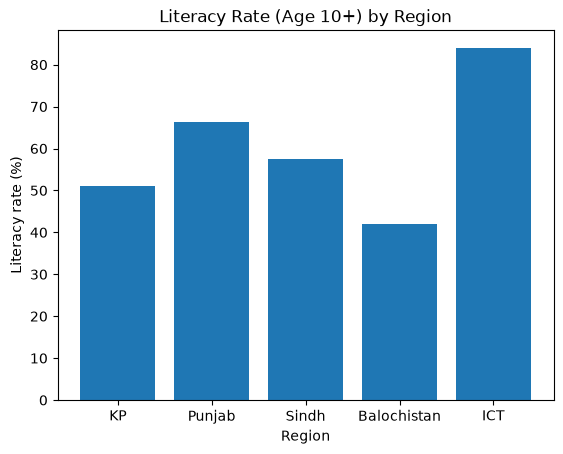

Finding: ICT is highest and Balochistan is lowest.


In [27]:
plt.bar(region_order, prov["literacy_pct"])
plt.title("Literacy Rate (Age 10+) by Region")
plt.xlabel("Region")
plt.ylabel("Literacy rate (%)")
plt.savefig("graphs/01_literacy_by_region.png", dpi=150, bbox_inches="tight")
plt.show()
print("Finding: ICT is highest and Balochistan is lowest.")

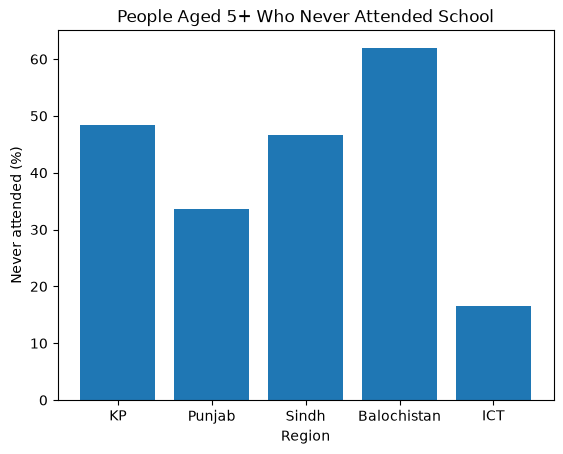

In [28]:
plt.bar(region_order, prov["never_attended_pct"])
plt.title("People Aged 5+ Who Never Attended School")
plt.xlabel("Region")
plt.ylabel("Never attended (%)")
plt.savefig("graphs/02_never_attended_by_region.png", dpi=150, bbox_inches="tight")
plt.show()

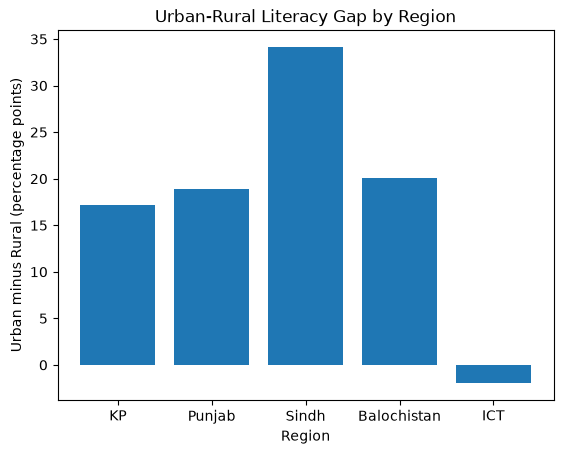

Finding: Sindh has the largest gap. In ICT, rural literacy is slightly higher than urban literacy.


In [29]:
plt.bar(region_order, area_table.loc[region_order, "gap_pp"])
plt.title("Urban-Rural Literacy Gap by Region")
plt.xlabel("Region")
plt.ylabel("Urban minus Rural (percentage points)")
plt.savefig("graphs/03_urban_rural_gap_by_region.png", dpi=150, bbox_inches="tight")
plt.show()
print("Finding: Sindh has the largest gap. In ICT, rural literacy is slightly higher than urban literacy.")

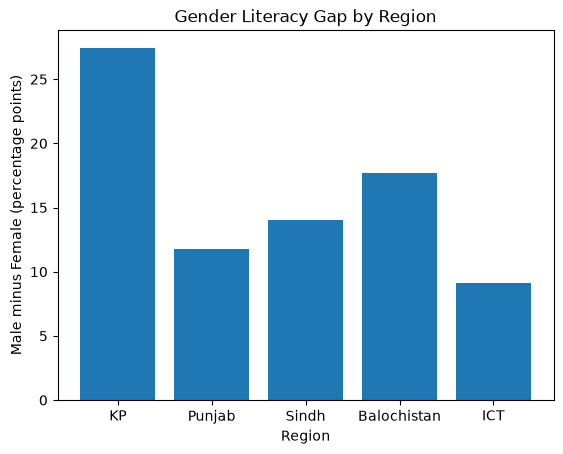

Finding: KP has the largest gender gap and ICT has the smallest.


In [30]:
plt.bar(region_order, gender_table["gap_pp"])
plt.title("Gender Literacy Gap by Region")
plt.xlabel("Region")
plt.ylabel("Male minus Female (percentage points)")
plt.savefig("graphs/04_gender_gap_by_region.png", dpi=150, bbox_inches="tight")
plt.show()
print("Finding: KP has the largest gender gap and ICT has the smallest.")

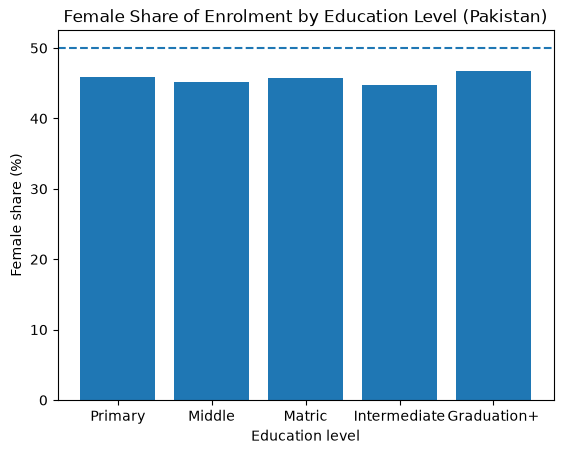

Finding: the female share is between 44.7 % and 46.7 % at every level, always below the 50% line.


In [31]:
plt.bar(level_labels, female_share_levels)
plt.axhline(50, linestyle="--")
plt.title("Female Share of Enrolment by Education Level (Pakistan)")
plt.xlabel("Education level")
plt.ylabel("Female share (%)")
plt.savefig("graphs/05_female_share_of_enrolment.png", dpi=150, bbox_inches="tight")
plt.show()
print("Finding: the female share is between", round(min(female_share_levels), 1), "% and", round(max(female_share_levels), 1),
      "% at every level, always below the 50% line.")

### 6.2 Grouped bar charts

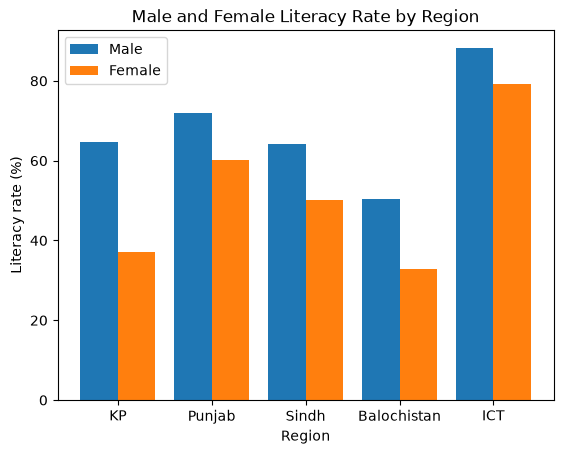

In [32]:
x = np.arange(len(region_order))
width = 0.4

plt.bar(x - width / 2, gender_table["Male"], width, label="Male")
plt.bar(x + width / 2, gender_table["Female"], width, label="Female")
plt.xticks(x, region_order)
plt.title("Male and Female Literacy Rate by Region")
plt.xlabel("Region")
plt.ylabel("Literacy rate (%)")
plt.legend()
plt.savefig("graphs/06_male_female_literacy_by_region.png", dpi=150, bbox_inches="tight")
plt.show()

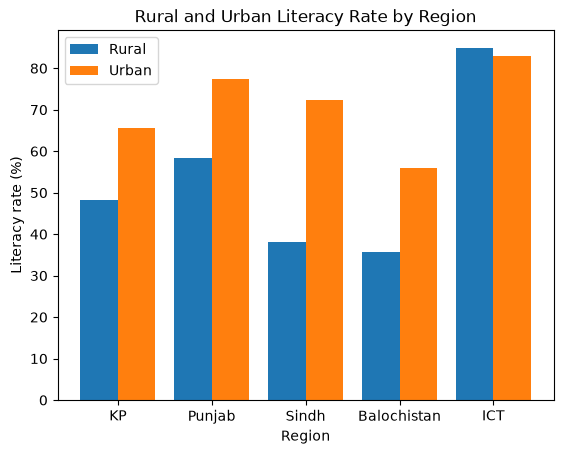

In [33]:
plt.bar(x - width / 2, area_table.loc[region_order, "Rural"], width, label="Rural")
plt.bar(x + width / 2, area_table.loc[region_order, "Urban"], width, label="Urban")
plt.xticks(x, region_order)
plt.title("Rural and Urban Literacy Rate by Region")
plt.xlabel("Region")
plt.ylabel("Literacy rate (%)")
plt.legend()
plt.savefig("graphs/07_rural_urban_literacy_by_region.png", dpi=150, bbox_inches="tight")
plt.show()

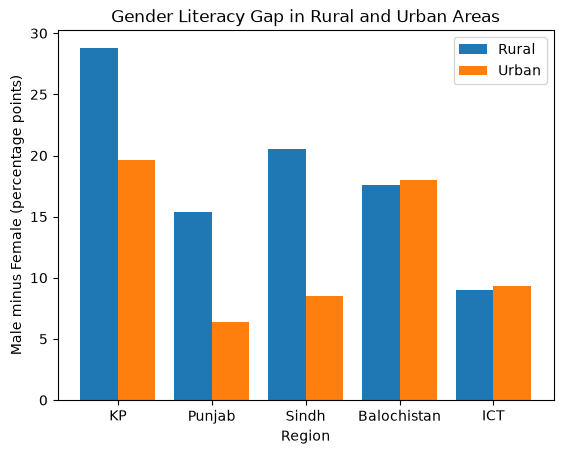

Finding: the gender gap is clearly bigger in rural areas in KP, Punjab and Sindh. In Balochistan and ICT, rural and urban gaps are about the same.


In [34]:
plt.bar(x - width / 2, rural_urban_gaps["Rural"], width, label="Rural")
plt.bar(x + width / 2, rural_urban_gaps["Urban"], width, label="Urban")
plt.xticks(x, region_order)
plt.title("Gender Literacy Gap in Rural and Urban Areas")
plt.xlabel("Region")
plt.ylabel("Male minus Female (percentage points)")
plt.legend()
plt.savefig("graphs/08_gender_gap_rural_urban.png", dpi=150, bbox_inches="tight")
plt.show()
print("Finding: the gender gap is clearly bigger in rural areas in KP, Punjab and Sindh. In Balochistan and ICT, rural and urban gaps are about the same.")

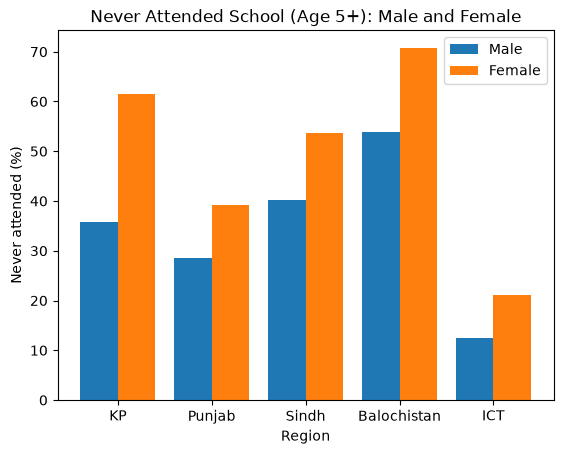

In [35]:
# Never attended % for males and females in each region
never_gender = provinces[provinces["area"] == "All"]
never_gender = never_gender[never_gender["sex"].isin(["Male", "Female"])]
never_gender = never_gender.pivot_table(index="region", columns="sex", values="never_attended_pct").loc[region_order]

plt.bar(x - width / 2, never_gender["Male"], width, label="Male")
plt.bar(x + width / 2, never_gender["Female"], width, label="Female")
plt.xticks(x, region_order)
plt.title("Never Attended School (Age 5+): Male and Female")
plt.xlabel("Region")
plt.ylabel("Never attended (%)")
plt.legend()
plt.savefig("graphs/09_never_attended_male_female.png", dpi=150, bbox_inches="tight")
plt.show()

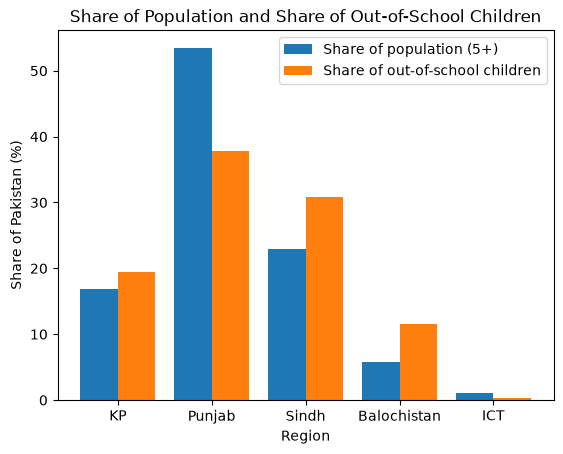

Finding: Punjab and ICT have a smaller share of out-of-school children than of population. KP, Sindh and Balochistan have a larger share.


In [36]:
plt.bar(x - width / 2, prov["share_of_population_pct"], width, label="Share of population (5+)")
plt.bar(x + width / 2, prov["share_of_oosc_pct"], width, label="Share of out-of-school children")
plt.xticks(x, region_order)
plt.title("Share of Population and Share of Out-of-School Children")
plt.xlabel("Region")
plt.ylabel("Share of Pakistan (%)")
plt.legend()
plt.savefig("graphs/10_population_vs_oosc_share.png", dpi=150, bbox_inches="tight")
plt.show()
print("Finding: Punjab and ICT have a smaller share of out-of-school children than of population. KP, Sindh and Balochistan have a larger share.")

### 6.3 Stacked bar charts

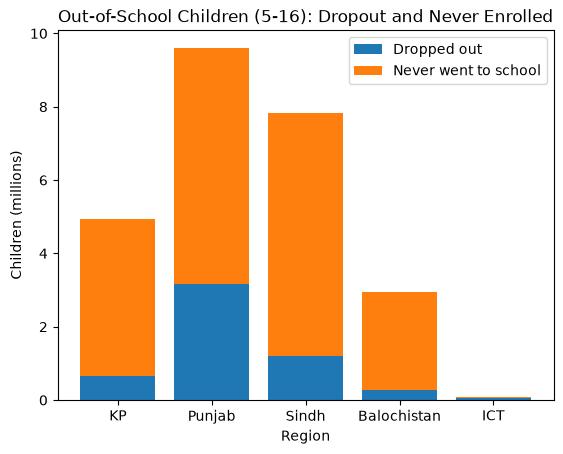

Finding: in KP, Punjab, Sindh and Balochistan most out-of-school children never went to school. Only in ICT are dropouts more common.


In [37]:
dropout_millions = prov["dropout_5_16"] / 1000000
never_millions = prov["never_school_5_16"] / 1000000

plt.bar(region_order, dropout_millions, label="Dropped out")
plt.bar(region_order, never_millions, bottom=dropout_millions, label="Never went to school")
plt.title("Out-of-School Children (5-16): Dropout and Never Enrolled")
plt.xlabel("Region")
plt.ylabel("Children (millions)")
plt.legend()
plt.savefig("graphs/11_oosc_dropout_never_stacked.png", dpi=150, bbox_inches="tight")
plt.show()
print("Finding: in KP, Punjab, Sindh and Balochistan most out-of-school children never went to school. Only in ICT are dropouts more common.")

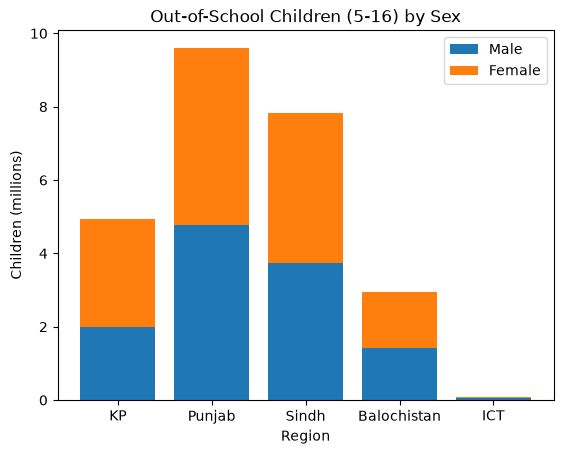

In [38]:
male_millions = oosc_by_sex["Male"] / 1000000
female_millions = oosc_by_sex["Female"] / 1000000

plt.bar(region_order, male_millions, label="Male")
plt.bar(region_order, female_millions, bottom=male_millions, label="Female")
plt.title("Out-of-School Children (5-16) by Sex")
plt.xlabel("Region")
plt.ylabel("Children (millions)")
plt.legend()
plt.savefig("graphs/12_oosc_by_sex_stacked.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.4 Histogram

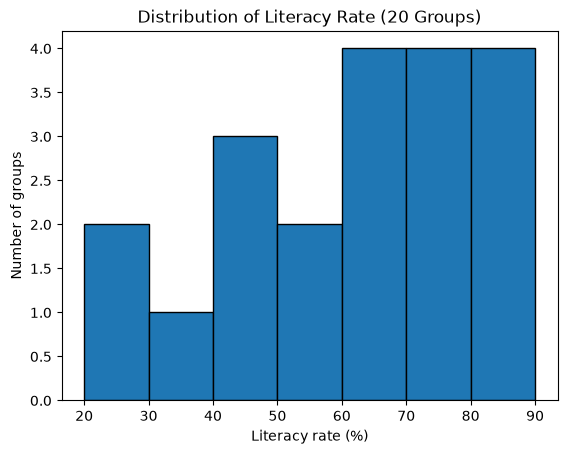

Finding: the most common class is 60-70 %, and the left tail is longer (negative skewness).


In [39]:
plt.hist(main_cells["literacy_pct"], bins=class_edges, edgecolor="black")
plt.title("Distribution of Literacy Rate (20 Groups)")
plt.xlabel("Literacy rate (%)")
plt.ylabel("Number of groups")
plt.savefig("graphs/13_histogram_literacy.png", dpi=150, bbox_inches="tight")
plt.show()
print("Finding: the most common class is", frequency.idxmax(), "%, and the left tail is longer (negative skewness).")

### 6.5 Box plots

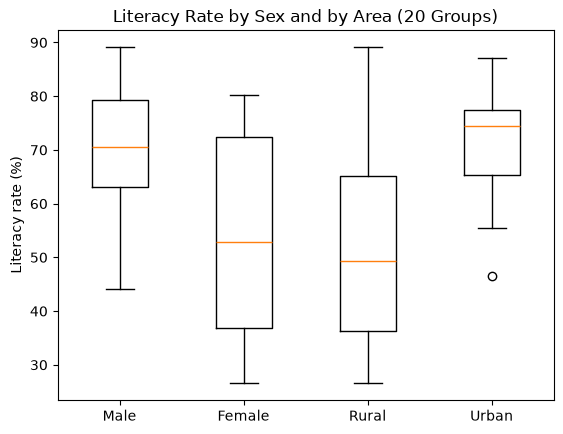

Finding: female and rural boxes sit lower and are wider, so those groups are lower and more spread out.
The dot in the Urban box is Balochistan urban females (46.5%). It is low compared with other urban groups, but it is a real value, so it is kept.


In [40]:
male_values = main_cells[main_cells["sex"] == "Male"]["literacy_pct"]
female_values = main_cells[main_cells["sex"] == "Female"]["literacy_pct"]
rural_values = main_cells[main_cells["area"] == "Rural"]["literacy_pct"]
urban_values = main_cells[main_cells["area"] == "Urban"]["literacy_pct"]

plt.boxplot([male_values, female_values, rural_values, urban_values])
plt.xticks([1, 2, 3, 4], ["Male", "Female", "Rural", "Urban"])
plt.title("Literacy Rate by Sex and by Area (20 Groups)")
plt.ylabel("Literacy rate (%)")
plt.savefig("graphs/14_boxplot_sex_area.png", dpi=150, bbox_inches="tight")
plt.show()
print("Finding: female and rural boxes sit lower and are wider, so those groups are lower and more spread out.")
print("The dot in the Urban box is Balochistan urban females (46.5%). It is low compared with other urban groups, but it is a real value, so it is kept.")

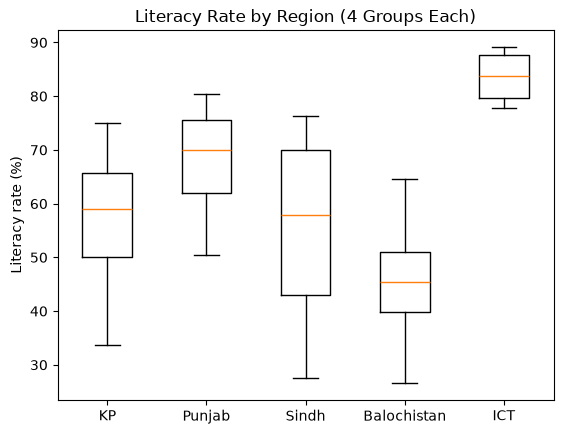

In [41]:
data_by_region = []
for name in region_order:
    values = main_cells[main_cells["region"] == name]["literacy_pct"]
    data_by_region.append(values)

plt.boxplot(data_by_region)
plt.xticks([1, 2, 3, 4, 5], region_order)
plt.title("Literacy Rate by Region (4 Groups Each)")
plt.ylabel("Literacy rate (%)")
plt.savefig("graphs/15_boxplot_by_region.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.6 Pie charts
Pie charts are used only for parts of a whole.

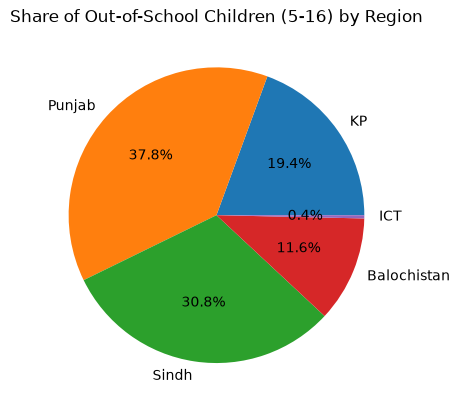

In [42]:
plt.pie(prov["oosc_5_16"], labels=region_order, autopct="%1.1f%%")
plt.title("Share of Out-of-School Children (5-16) by Region")
plt.savefig("graphs/16_pie_oosc_by_region.png", dpi=150, bbox_inches="tight")
plt.show()

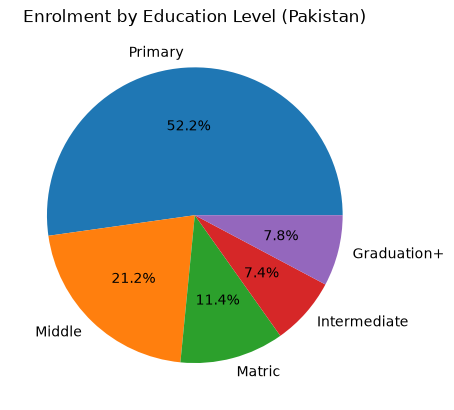

In [43]:
enrolment_totals = pakistan_all.loc["Total", levels]

plt.pie(enrolment_totals, labels=level_labels, autopct="%1.1f%%")
plt.title("Enrolment by Education Level (Pakistan)")
plt.savefig("graphs/17_pie_enrolment_by_level.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.7 Scatter plots

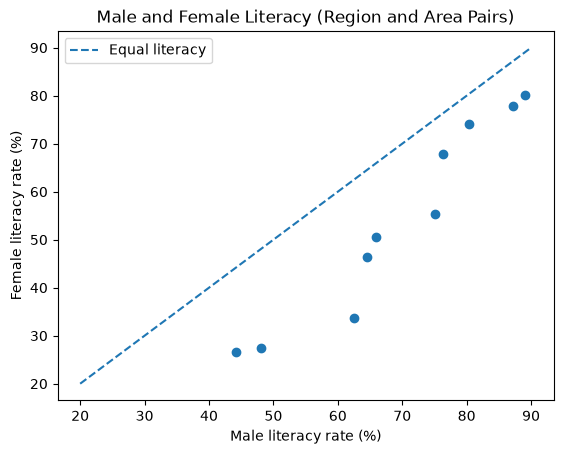

Finding: every point is below the dashed line, so female literacy is lower than male literacy in every region and area.


In [44]:
plt.scatter(male_female["Male"], male_female["Female"])
plt.plot([20, 90], [20, 90], linestyle="--", label="Equal literacy")
plt.title("Male and Female Literacy (Region and Area Pairs)")
plt.xlabel("Male literacy rate (%)")
plt.ylabel("Female literacy rate (%)")
plt.legend()
plt.savefig("graphs/18_scatter_male_vs_female.png", dpi=150, bbox_inches="tight")
plt.show()
print("Finding: every point is below the dashed line, so female literacy is lower than male literacy in every region and area.")

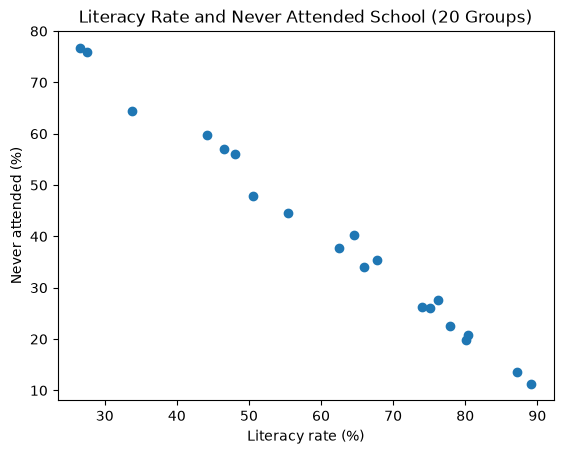

In [45]:
plt.scatter(main_cells["literacy_pct"], main_cells["never_attended_pct"])
plt.title("Literacy Rate and Never Attended School (20 Groups)")
plt.xlabel("Literacy rate (%)")
plt.ylabel("Never attended (%)")
plt.savefig("graphs/19_scatter_literacy_vs_never_attended.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.8 Heatmaps (made with Matplotlib)

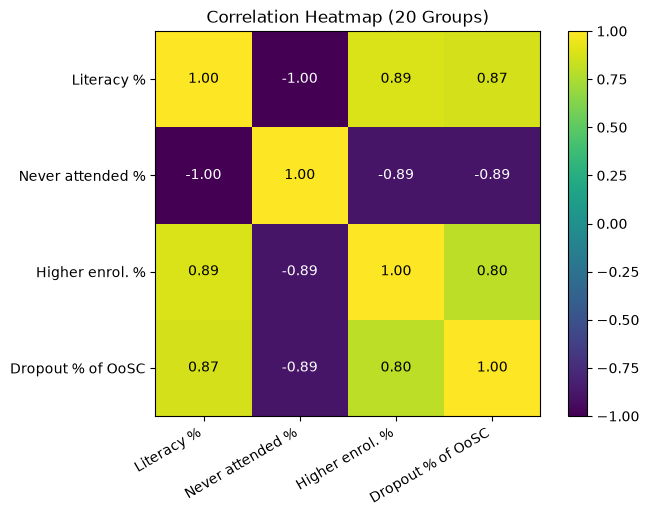

In [46]:
heat_names = ["Literacy %", "Never attended %", "Higher enrol. %", "Dropout % of OoSC"]
heat_values = correlation.values

plt.figure(figsize=(7, 5))
plt.imshow(heat_values, vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(4), heat_names, rotation=30, ha="right")
plt.yticks(range(4), heat_names)

# Write the number inside each box
for i in range(4):
    for j in range(4):
        value = heat_values[i, j]
        if value < 0.5:
            text_color = "white"
        else:
            text_color = "black"
        plt.text(j, i, format(value, ".2f"), ha="center", va="center", color=text_color)

plt.title("Correlation Heatmap (20 Groups)")
plt.savefig("graphs/20_heatmap_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

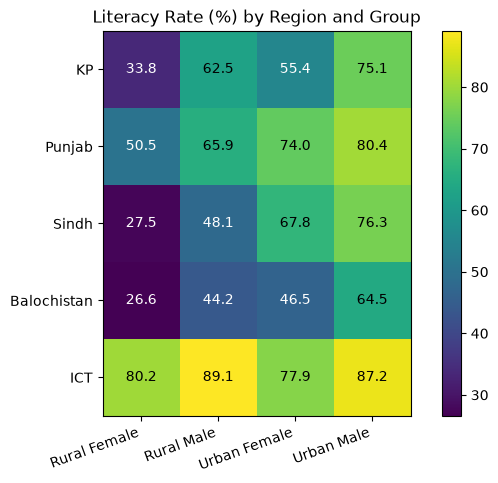

Finding: the darkest boxes (lowest literacy) are rural females in Balochistan, Sindh and KP.


In [47]:
table_values = literacy_table.values
column_names = list(literacy_table.columns)

plt.figure(figsize=(8, 5))
plt.imshow(table_values)
plt.colorbar()
plt.xticks(range(len(column_names)), column_names, rotation=20, ha="right")
plt.yticks(range(len(region_order)), region_order)

for i in range(len(region_order)):
    for j in range(len(column_names)):
        value = table_values[i, j]
        if value < 60:
            text_color = "white"
        else:
            text_color = "black"
        plt.text(j, i, str(round(value, 1)), ha="center", va="center", color=text_color)

plt.title("Literacy Rate (%) by Region and Group")
plt.savefig("graphs/21_heatmap_literacy_groups.png", dpi=150, bbox_inches="tight")
plt.show()
print("Finding: the darkest boxes (lowest literacy) are rural females in Balochistan, Sindh and KP.")

## Step 7: Final answers
All numbers below come from the data above.

In [48]:
print("Q1. GENDER GAP")
print("Male literacy is", round(national.loc["All", "Male"], 1), "% and female literacy is", round(national.loc["All", "Female"], 1), "%.")
print("The gap is", round(national.loc["All", "gap_pp"], 1), "percentage points (female/male ratio =", round(national.loc["All", "parity"], 2), ").")
print("Females are", round(female_share_never, 1), "% of people who never attended school.")
print()

print("Q2. BEST AND WORST REGION")
print("Highest literacy:", prov["literacy_pct"].idxmax(), "-", round(prov["literacy_pct"].max(), 1), "%")
print("Lowest literacy:", prov["literacy_pct"].idxmin(), "-", round(prov["literacy_pct"].min(), 1), "%")
print("Best average rank:", rank_table["average_rank"].idxmin(), "| Worst average rank:", rank_table["average_rank"].idxmax())
print()

print("Q3. URBAN-RURAL GAP")
print("Urban literacy is", round(area_table.loc["Pakistan", "Urban"], 1), "% and rural literacy is", round(area_table.loc["Pakistan", "Rural"], 1), "%.")
print("The gap is", round(area_table.loc["Pakistan", "gap_pp"], 1), "percentage points. Largest gap:", region_gaps.idxmax(), "(", round(region_gaps.max(), 1), "pp ).")
print()

print("Q4. GENDER GAP ACROSS REGIONS")
print(gender_table[["gap_pp", "parity"]].round(2))
print()

print("Q5. GREATEST DISADVANTAGE")
print("Lowest Male/Female group:", worst["area"], worst["sex"], "in", worst["region"], "-", round(worst["literacy_pct"], 1), "% literate.")
for name in region_order:
    one_region = main_cells[main_cells["region"] == name]
    lowest_one = one_region.sort_values("literacy_pct").iloc[0]
    print("Lowest group in", name, ":", lowest_one["group"], "(", round(lowest_one["literacy_pct"], 1), "% )")

Q1. GENDER GAP
Male literacy is 68.0 % and female literacy is 52.8 %.
The gap is 15.2 percentage points (female/male ratio = 0.78 ).
Females are 57.1 % of people who never attended school.

Q2. BEST AND WORST REGION
Highest literacy: ICT - 84.0 %
Lowest literacy: Balochistan - 42.0 %
Best average rank: ICT | Worst average rank: Balochistan

Q3. URBAN-RURAL GAP
Urban literacy is 74.1 % and rural literacy is 51.6 %.
The gap is 22.5 percentage points. Largest gap: Sindh ( 34.1 pp ).

Q4. GENDER GAP ACROSS REGIONS
sex          gap_pp  parity
region                     
KP            27.43    0.58
Punjab        11.79    0.84
Sindh         14.02    0.78
Balochistan   17.70    0.65
ICT            9.10    0.90

Q5. GREATEST DISADVANTAGE
Lowest Male/Female group: Rural Female in Balochistan - 26.6 % literate.
Lowest group in KP : Rural Female ( 33.8 % )
Lowest group in Punjab : Rural Female ( 50.5 % )
Lowest group in Sindh : Rural Female ( 27.5 % )
Lowest group in Balochistan : Rural Female ( 2

## Limitations
- The data is for one census year, so we cannot study change over time.
- The population aged 5-16 is not in the table, so we cannot calculate an out-of-school **rate**; we use counts and shares.
- "Never attended" includes young children who have not started school yet.
- Transgender groups are very small, so they are described but not compared.
- Averages across regions are simple averages (not weighted by population).
- Correlation shows a link, not a cause.